In [9]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from keras.models import load_model

print("=== EVALUADOR DE MODELOS PRE-5.0 (SIN OPCIÓN DE RECHAZO) ===")

# 1. CARGA DE DATOS DESDE EL PACIENTE O DATASET UNIFICADO
# Cambia esta ruta al paciente que desees probar (ej. 'Data\Raw_data\108.npz')
ruta_npz = r'Data\Raw_data\100.npz' 

try:
    datos = np.load(ruta_npz)
    X_test = datos['X']
    Y_reales = datos['Y']
    print(f"-> Total de latidos cargados: {len(X_test)}")
except Exception as e:
    print(f"Error al cargar los datos: {e}")

# Expandir dimensión para la CNN (N, 6, 54) -> (N, 6, 54, 1)
X_cnn = np.expand_dims(X_test, axis=-1)

=== EVALUADOR DE MODELOS PRE-5.0 (SIN OPCIÓN DE RECHAZO) ===
-> Total de latidos cargados: 2272


In [10]:
# 2. MAPEO DE CLASES (Las 8 originales del Jupyter anterior)
clases_viables = ['N', '/', 'R', 'L', 'V', 'A', 'f', 'F']
etiquetas_finales = clases_viables + ['No_Clasificable']

mapeo_clases = {clase: i for i, clase in enumerate(clases_viables)}

# Todo lo que no pertenezca a 'clases_viables' se etiqueta como 8 ('No_Clasificable')
# Esto nos permite retener TODAS las muestras del paciente
Y_reales_numericas = np.array([mapeo_clases.get(etiqueta, 8) for etiqueta in Y_reales])

conteo_inclasificables = np.sum(Y_reales_numericas == 8)
print(f"-> Latidos clasificados como 'No_Clasificable' en la realidad: {conteo_inclasificables}")

-> Latidos clasificados como 'No_Clasificable' en la realidad: 1


In [11]:
# 3. CARGAR MODELO ANTIGUO
# Dado que es pre-5.0, no necesitamos la custom_loss. Keras lo carga nativamente.
ruta_modelo = r'Data\Models\modelo_arritmias_cnn_2.0.keras'
modelo = load_model(ruta_modelo)

# 4. INFERENCIA
print("\nRealizando inferencia... El modelo elegirá a la fuerza entre 8 clases.")
y_pred_prob = modelo.predict(X_cnn)

# El modelo sacará un número entre 0 y 7
y_pred_clases = np.argmax(y_pred_prob, axis=1)


Realizando inferencia... El modelo elegirá a la fuerza entre 8 clases.
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


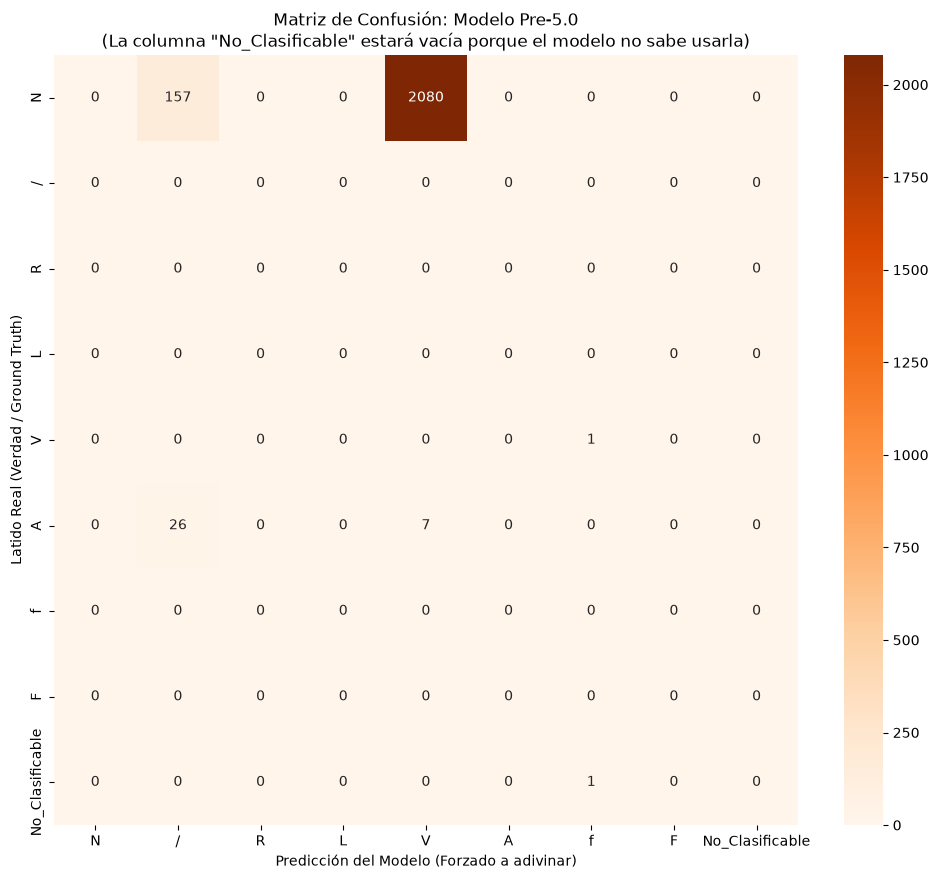


=== REPORTE DE CLASIFICACIÓN ===
                 precision    recall  f1-score   support

              N       0.00      0.00      0.00    2237.0
              /       0.00      0.00      0.00       0.0
              R       0.00      0.00      0.00       0.0
              L       0.00      0.00      0.00       0.0
              V       0.00      0.00      0.00       1.0
              A       0.00      0.00      0.00      33.0
              f       0.00      0.00      0.00       0.0
              F       0.00      0.00      0.00       0.0
No_Clasificable       0.00      0.00      0.00       1.0

       accuracy                           0.00    2272.0
      macro avg       0.00      0.00      0.00    2272.0
   weighted avg       0.00      0.00      0.00    2272.0



In [12]:
# 5. MATRIZ DE CONFUSIÓN Y GRÁFICAS
# Forzamos labels=np.arange(9) para generar una cuadrícula 9x9
matriz_conf = confusion_matrix(Y_reales_numericas, y_pred_clases, labels=np.arange(9))

plt.figure(figsize=(12, 10))
# Usamos un mapa de calor distinto (ej. Oranges o Reds) para diferenciar de tu otro notebook
sns.heatmap(matriz_conf, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=etiquetas_finales, yticklabels=etiquetas_finales)

plt.title(f'Matriz de Confusión: Modelo Pre-5.0\n(La columna "No_Clasificable" estará vacía porque el modelo no sabe usarla)')
plt.ylabel('Latido Real (Verdad / Ground Truth)')
plt.xlabel('Predicción del Modelo (Forzado a adivinar)')
plt.show()

# 6. REPORTE DE CLASIFICACIÓN
print("\n=== REPORTE DE CLASIFICACIÓN ===")
# zero_division=0 es clave aquí para que no marque errores en la clase que el modelo nunca predice
print(classification_report(Y_reales_numericas, y_pred_clases, 
                            target_names=etiquetas_finales, 
                            labels=np.arange(9), 
                            zero_division=0))